# 01 - BEA: US State Economic Data

The purpose of this notebook is to inspect, validate, and prepare selected Bureau of Economic Analysis (BEA) state-level economic indicators for 2014–2025, producing reusable datasets for subsequent analysis.

**Source:** [BEA Regional Data — GDP and Personal Income](https://www.bea.gov/itable/regional-gdp-and-personal-income) · [BEA regional downloadable files](https://apps.bea.gov/regional/downloadzip.htm)

**Research questions**
- Which relevant economic indicators and industry breakdowns are available for each state and year?
- Are the selected data complete, consistent, and comparable across states and 2014–2025?
- What broad differences and trends appear in the prepared indicators?



In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


## 1. Data source and scope


### 1.1 Data source

The Bureau of Economic Analysis (BEA) provides official US economic statistics, including GDP, personal income, population, and economic activity by industry.

**Source:** https://apps.bea.gov/regional/downloadzip.htm

This notebook uses four annual state-level tables:

- **SAGDP1:** GDP summary indicators.
- **SAGDP2:** GDP by industry.
- **SAGDP9:** Real GDP by industry.
- **SAINC1:** Personal income and population.

The analysis covers US states over **2014–2025**. These data will later be combined with documented cybersecurity incidents to explore relationships between economic characteristics and incident frequency.


In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
BEA_DIR = PROJECT_ROOT / "data" / "raw" / "bea" / "extracted"

tables = {
    "SAGDP1": BEA_DIR / "SAGDP" / "SAGDP1__ALL_AREAS_1997_2025.csv",
    "SAGDP2": BEA_DIR / "SAGDP" / "SAGDP2__ALL_AREAS_1997_2025.csv",
    "SAGDP9": BEA_DIR / "SAGDP" / "SAGDP9__ALL_AREAS_1997_2025.csv",
    "SAINC1": BEA_DIR / "SAINC" / "SAINC1__ALL_AREAS_1929_2025.csv",
}

file_overview = pd.DataFrame([
    {
        "table": name,
        "exists": path.is_file(),
        "size_mb": round(path.stat().st_size / 1024**2, 2)
        if path.is_file() else np.nan,
        "filename": path.name,
    }
    for name, path in tables.items()
])

display(file_overview)


,table,exists,size_mb,filename
0,SAGDP1,True,0.16,SAGDP1__ALL_AREAS_1997_2025.csv
1,SAGDP2,True,1.66,SAGDP2__ALL_AREAS_1997_2025.csv
2,SAGDP9,True,1.69,SAGDP9__ALL_AREAS_1997_2025.csv
3,SAINC1,True,0.13,SAINC1__ALL_AREAS_1929_2025.csv


## 2. Data overview


### 2.1 Dataset structure

We inspect the structure of the four BEA tables to identify their columns, geographic identifiers, annual observations, and economic indicators relevant to the research.


In [3]:
# Inspect the structure of each BEA table
bea_tables = {}

for name, path in tables.items():
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    bea_tables[name] = df

structure_overview = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "column_names": ", ".join(df.columns[:12]),
    }
    for name, df in bea_tables.items()
])

display(structure_overview)


,table,rows,columns,column_names
0,SAGDP1,484,37,"GeoFIPS, GeoName, Region, TableName, LineCode,..."
1,SAGDP2,5528,37,"GeoFIPS, GeoName, Region, TableName, LineCode,..."
2,SAGDP9,5524,37,"GeoFIPS, GeoName, Region, TableName, LineCode,..."
3,SAINC1,184,105,"GeoFIPS, GeoName, Region, TableName, LineCode,..."


In [4]:
# Inspect geographic identifiers, indicators, and measurement units
columns = [
    "GeoFIPS", "GeoName", "LineCode",
    "Description", "Unit"
]

display(
    bea_tables["SAGDP1"][columns].head(12)
)


,GeoFIPS,GeoName,LineCode,Description,Unit
0,"""00000""",United States,1.0,Real GDP (millions of chained 2017 dollars) 1/,Millions of chained 2017 dollars
1,"""00000""",United States,2.0,Chain-type quantity indexes for real GDP,Quantity index
2,"""00000""",United States,3.0,Current-dollar GDP (millions of current dollars),Millions of current dollars
3,"""00000""",United States,4.0,Compensation (millions of dollars),Millions of current dollars
4,"""00000""",United States,5.0,Gross operating surplus (millions of dollars),Millions of current dollars
5,"""00000""",United States,6.0,Taxes on production and imports (TOPI) less su...,Millions of current dollars
6,"""00000""",United States,7.0,Taxes on production and imports (TOPI) (milli...,Millions of current dollars
7,"""00000""",United States,8.0,Subsidies (millions of dollars),Millions of current dollars
8,"""01000""",Alabama,1.0,Real GDP (millions of chained 2017 dollars) 1/,Millions of chained 2017 dollars
9,"""01000""",Alabama,2.0,Chain-type quantity indexes for real GDP,Quantity index


### 2.2 Relevant economic indicators

We identify the economic indicators available in each BEA table and select those relevant to economic size, income, population, and industry structure.


In [5]:
# List the available indicators in each BEA table
indicator_overview = pd.concat([
    df[["LineCode", "Description", "Unit"]]
    .dropna(subset=["LineCode"])
    .drop_duplicates()
    .assign(table=name)
    for name, df in bea_tables.items()
], ignore_index=True)

display(
    indicator_overview[
        ["table", "LineCode", "Description", "Unit"]
    ].to_string(index=False)
)


' table  LineCode                                                                                  Description                             Unit\nSAGDP1       1.0                                               Real GDP (millions of chained 2017 dollars) 1/ Millions of chained 2017 dollars\nSAGDP1       2.0                                                    Chain-type quantity indexes for real GDP                    Quantity index\nSAGDP1       3.0                                            Current-dollar GDP (millions of current dollars)       Millions of current dollars\nSAGDP1       4.0                                                          Compensation (millions of dollars)       Millions of current dollars\nSAGDP1       5.0                                               Gross operating surplus (millions of dollars)       Millions of current dollars\nSAGDP1       6.0                  Taxes on production and imports (TOPI) less subsides (millions of dollars)       Millions of current 

### 2.2 Selected economic indicators

The analysis focuses on economic size, income, population, growth, and industry structure.

**State-level indicators:**
- Nominal GDP and real GDP
- Personal income and personal income per capita
- Population
- GDP per capita (derived)
- Annual real GDP growth (derived)

**Industry-level indicators:**

Ten industries are selected from SAGDP2, covering utilities, manufacturing, retail, transportation, information, finance, professional services, education, healthcare, and government.

For each industry, nominal GDP and its percentage contribution to total state GDP will be retained.

These indicators provide a foundation for examining differences in documented cybersecurity incidents across states, years, and economic sectors.


## 3. Data quality

Data quality checks focus on geographic and temporal coverage, missing values, and duplicate records. Only the economic indicators selected for the analysis are considered.



### 3.1 Geographic and temporal coverage

The target dataset covers the 50 US states from 2014 to 2025, with one observation per state and year for each selected indicator.

Geographic identifiers, annual coverage, and the presence of non-state areas are examined before filtering the data.


In [6]:
# Selected indicators for data quality checks
selected_lines = {
    "SAGDP1": [1, 3],
    "SAGDP2": [10, 12, 35, 36, 45, 51, 60, 69, 70, 83],
    "SAINC1": [1, 2, 3],
}

years = [str(year) for year in range(2014, 2026)]

coverage = []

for name, codes in selected_lines.items():
    df = bea_tables[name].copy()
    df = df[df["LineCode"].isin(codes)]
    
    coverage.append({
        "table": name,
        "indicators": df["LineCode"].nunique(),
        "geographic_areas": df["GeoFIPS"].nunique(),
        "first_year": min(int(y) for y in years if y in df.columns),
        "last_year": max(int(y) for y in years if y in df.columns),
        "rows": len(df),
    })

display(pd.DataFrame(coverage))


,table,indicators,geographic_areas,first_year,last_year,rows
0,SAGDP1,2,60,2014,2025,120
1,SAGDP2,10,60,2014,2025,600
2,SAINC1,3,60,2014,2025,180


In [7]:

# Inspect all geographic areas in the BEA dataset
geographic_areas = (
    bea_tables["SAGDP1"][["GeoFIPS", "GeoName", "Region"]]
    .drop_duplicates()
    .sort_values("GeoName")
    .reset_index(drop=True)
)

display(geographic_areas)


,GeoFIPS,GeoName,Region
0,"""01000""",Alabama,5
1,"""02000""",Alaska,8
2,"""04000""",Arizona,6
3,"""05000""",Arkansas,5
4,"""06000""",California,8
...,...,...,...
59,"""56000""",Wyoming,7
60,Note: See the included footnote file.,NaN,NaN
61,SAGDP1: State annual gross domestic product (G...,NaN,NaN
62,"Last updated: September 30, 2026-- revised sta...",NaN,NaN


In [8]:
state_fips_codes = {
    "01", "02", "04", "05", "06", "08", "09", "10", "12", "13",
    "15", "16", "17", "18", "19", "20", "21", "22", "23", "24",
    "25", "26", "27", "28", "29", "30", "31", "32", "33", "34",
    "35", "36", "37", "38", "39", "40", "41", "42", "44", "45",
    "46", "47", "48", "49", "50", "51", "53", "54", "55", "56"
}



In [9]:
# Normalize geographic identifiers
geo = geographic_areas.copy()

geo["state_fips"] = (
    geo["GeoFIPS"]
    .astype(str)
    .str.strip()
    .str.strip('"')
    .str[:2]
)

geo["is_state"] = geo["state_fips"].isin(state_fips_codes)

print("US states:", geo["is_state"].sum())

display(
    geo.loc[
        ~geo["is_state"],
        ["GeoFIPS", "GeoName"]
    ]
)


US states: 50


,GeoFIPS,GeoName
8,"""11000""",District of Columbia
9,"""98000""",Far West
12,"""93000""",Great Lakes
25,"""92000""",Mideast
32,"""91000""",New England
43,"""94000""",Plains
45,"""97000""",Rocky Mountain
48,"""95000""",Southeast
49,"""96000""",Southwest
52,"""00000""",United States


### 3.2 Missing values and duplicates

The quality assessment focuses on the selected indicators for the 50 US states between 2014 and 2025.

Missing observations, non-numeric values, and duplicate state–indicator combinations are checked before data preparation.


In [10]:
# Check selected indicators across the 50 states and 12 years
quality_results = []

for name, codes in selected_lines.items():
    df = bea_tables[name].copy()

    df["state_fips"] = (
        df["GeoFIPS"].astype(str).str.strip().str.strip('"').str[:2]
    )

    df = df[
        df["state_fips"].isin(state_fips_codes)
        & df["LineCode"].isin(codes)
    ]

    values = df[years].apply(pd.to_numeric, errors="coerce")

    quality_results.append({
        "table": name,
        "states": df["state_fips"].nunique(),
        "indicators": df["LineCode"].nunique(),
        "observations": values.size,
        "missing_values": values.isna().sum().sum(),
        "missing_pct": round(100 * values.isna().sum().sum() / values.size, 2),
        "duplicates": df.duplicated(["state_fips", "LineCode"]).sum(),
    })

display(pd.DataFrame(quality_results))


,table,states,indicators,observations,missing_values,missing_pct,duplicates
0,SAGDP1,50,2,1200,0,0.0,0
1,SAGDP2,50,10,6000,0,0.0,0
2,SAINC1,50,3,1800,0,0.0,0


## 4. Data preparation and visualization

The selected BEA indicators are transformed into analysis-ready datasets for 50 US states over 2014–2025. Derived economic measures and industry GDP shares are calculated before visualizing the results.

### 4.1 State-level economic indicators

GDP, personal income, and population data are combined into a state–year panel. Monetary GDP and total income values are converted from millions of dollars to dollars to ensure consistent units.

GDP per capita and annual real GDP growth are derived to support comparisons across states and over time.


In [11]:

# Select and reshape state-level economic indicators
indicator_names = {
    ("SAGDP1", 1): "gdp_real",
    ("SAGDP1", 3): "gdp_nominal",
    ("SAINC1", 1): "personal_income",
    ("SAINC1", 2): "population",
    ("SAINC1", 3): "personal_income_per_capita",
}

frames = []

for name in ["SAGDP1", "SAINC1"]:
    df = bea_tables[name].copy()

    df["state_fips"] = (
        df["GeoFIPS"].astype(str).str.strip().str.strip('"').str[:2]
    )

    df = df[
        df["state_fips"].isin(state_fips_codes)
        & df["LineCode"].isin(selected_lines[name])
    ]

    df = df.melt(
        id_vars=["state_fips", "LineCode"],
        value_vars=years,
        var_name="year",
        value_name="value"
    )

    df["indicator"] = df["LineCode"].map(
        lambda code: indicator_names[(name, int(code))]
    )

    frames.append(df)

economic_long = pd.concat(frames, ignore_index=True)
economic_long["year"] = economic_long["year"].astype(int)
economic_long["value"] = pd.to_numeric(economic_long["value"])

# Create one row per state and year
economic_state = (
    economic_long.pivot(
        index=["state_fips", "year"],
        columns="indicator",
        values="value"
    )
    .reset_index()
)

economic_state.columns.name = None

# Standardize state names using SAGDP1
state_names = (
    bea_tables["SAGDP1"][["GeoFIPS", "GeoName"]]
    .assign(
        state_fips=lambda df: (
            df["GeoFIPS"].astype(str).str.strip().str.strip('"').str[:2]
        )
    )
    .loc[lambda df: df["state_fips"].isin(state_fips_codes)]
    [["state_fips", "GeoName"]]
    .drop_duplicates(subset=["state_fips"])
    .rename(columns={"GeoName": "state"})
)

economic_state = economic_state.merge(
    state_names,
    on="state_fips",
    how="left",
    validate="many_to_one"
)

# Convert monetary totals from millions to dollars
for column in ["gdp_nominal", "gdp_real", "personal_income"]:
    economic_state[column] *= 1_000_000

economic_state["gdp_per_capita"] = (
    economic_state["gdp_nominal"] / economic_state["population"]
)

economic_state = economic_state[
    [
        "state_fips", "state", "year",
        "gdp_nominal", "gdp_real",
        "personal_income", "population",
        "personal_income_per_capita", "gdp_per_capita"
    ]
].sort_values(["state_fips", "year"]).reset_index(drop=True)

assert economic_state.shape[0] == 600
assert not economic_state.duplicated(["state_fips", "year"]).any()
assert economic_state.notna().all().all()

display(economic_state.head())


,state_fips,state,year,gdp_nominal,gdp_real,personal_income,population,personal_income_per_capita,gdp_per_capita
0,01,Alabama,2014,1.970644e+11,2.060700e+11,1.794295e+11,4887757.0,36710.0,40317.961797
1,01,Alabama,2015,2.031133e+11,2.089503e+11,1.874171e+11,4909177.0,38177.0,41374.205901
2,01,Alabama,2016,2.088243e+11,2.128628e+11,1.908120e+11,4931579.0,38692.0,42344.307979
3,01,Alabama,2017,2.166155e+11,2.166155e+11,1.979006e+11,4953096.0,39955.0,43733.353846
4,01,Alabama,2018,2.262638e+11,2.207846e+11,2.056250e+11,4977088.0,41314.0,45461.080857


### Annual real GDP growth

Annual real GDP growth measures the percentage change in inflation-adjusted economic output relative to the previous year.$$\text{Real GDP growth (\%)} = \frac{\text{Real GDP}_t - \text{Real GDP}_{t-1}}{\text{Real GDP}_{t-1}} \times 100$$Real GDP values from 2013 are used to calculate growth for 2014, while the final dataset remains restricted to 2014–2025.

In [12]:
# Retrieve 2013 real GDP as the baseline for 2014 growth
gdp_2013 = bea_tables["SAGDP1"].copy()

gdp_2013["state_fips"] = (
    gdp_2013["GeoFIPS"].astype(str).str.strip().str.strip('"').str[:2]
)

gdp_2013 = gdp_2013.loc[
    gdp_2013["state_fips"].isin(state_fips_codes)
    & gdp_2013["LineCode"].eq(1),
    ["state_fips", "2013"]
].rename(columns={"2013": "gdp_real_2013"})

gdp_2013["gdp_real_2013"] = (
    pd.to_numeric(gdp_2013["gdp_real_2013"]) * 1_000_000
)

economic_state = economic_state.merge(
    gdp_2013, on="state_fips", how="left", validate="many_to_one"
)

previous_gdp = economic_state.groupby("state_fips")["gdp_real"].shift(1)

previous_gdp = previous_gdp.fillna(economic_state["gdp_real_2013"])

economic_state["real_gdp_growth_pct"] = (
    (economic_state["gdp_real"] / previous_gdp - 1) * 100
)

economic_state = economic_state.drop(columns="gdp_real_2013")

assert economic_state["real_gdp_growth_pct"].notna().all()

display(
    economic_state.loc[
        economic_state["state"].eq("Alabama"),
        ["year", "gdp_real", "real_gdp_growth_pct"]
    ].head()
)


,year,gdp_real,real_gdp_growth_pct
0,2014,2.060700e+11,-0.431430
1,2015,2.089503e+11,1.397729
2,2016,2.128628e+11,1.872455
3,2017,2.166155e+11,1.762967
4,2018,2.207846e+11,1.924655


In [13]:
# Select the ten relevant sectors
sector_df = bea_tables["SAGDP2"].copy()

sector_df["state_fips"] = (
    sector_df["GeoFIPS"].astype(str).str.strip().str.strip('"').str[:2]
)

sector_df = sector_df.loc[
    sector_df["state_fips"].isin(state_fips_codes)
    & sector_df["LineCode"].isin(selected_lines["SAGDP2"])
]

# Reshape annual sector GDP values
economic_sectors = sector_df.melt(
    id_vars=["state_fips", "LineCode", "Description"],
    value_vars=years,
    var_name="year",
    value_name="sector_gdp"
)

economic_sectors["year"] = economic_sectors["year"].astype(int)
economic_sectors["sector_gdp"] = (
    pd.to_numeric(economic_sectors["sector_gdp"]) * 1_000_000
)

economic_sectors = economic_sectors.rename(
    columns={"Description": "sector"}
)

# Add state names and total nominal GDP
economic_sectors = economic_sectors.merge(
    economic_state[["state_fips", "state", "year", "gdp_nominal"]],
    on=["state_fips", "year"],
    how="left",
    validate="many_to_one"
)

# Calculate each sector's percentage of state GDP
economic_sectors["sector_gdp_share_pct"] = (
    100 * economic_sectors["sector_gdp"] / economic_sectors["gdp_nominal"]
)

economic_sectors = (
    economic_sectors[
        ["state_fips", "state", "year", "sector",
         "sector_gdp", "sector_gdp_share_pct"]
    ]
    .sort_values(["state_fips", "year", "sector"])
    .reset_index(drop=True)
)

assert len(economic_sectors) == 6000
assert economic_sectors.notna().all().all()
assert economic_sectors["sector_gdp_share_pct"].between(0, 100).all()

display(economic_sectors.head(10))


,state_fips,state,year,sector,sector_gdp,sector_gdp_share_pct
0,01,Alabama,2014,Educational services,1.262700e+09,0.640755
1,01,Alabama,2014,Finance and insurance,1.225120e+10,6.216851
2,01,Alabama,2014,Health care and social assistance,1.418360e+10,7.197444
3,01,Alabama,2014,"Professional, scientific, and technical ser...",1.138260e+10,5.776081
4,01,Alabama,2014,Information,4.235500e+09,2.149297
5,01,Alabama,2014,Manufacturing,3.295820e+10,16.724583
6,01,Alabama,2014,Retail trade,1.348040e+10,6.840606
7,01,Alabama,2014,Transportation and warehousing,5.124500e+09,2.600419
8,01,Alabama,2014,Utilities,5.908200e+09,2.998106
9,01,Alabama,2014,Government and government enterprises,3.310410e+10,16.798620



### 4.3 Selected visualizations




#### GDP per capita by US state (2025)

A choropleth map illustrates geographic differences in nominal GDP per capita across all 50 US states. GDP per capita accounts for population size, allowing more meaningful comparisons of economic output than total GDP alone.


In [23]:
# Figure output directories
FIGURES_DIR = PROJECT_ROOT / "figures" / "economic" / "bea"
STATIC_DIR = FIGURES_DIR / "static"
INTERACTIVE_DIR = FIGURES_DIR / "interactive"

STATIC_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_DIR.mkdir(parents=True, exist_ok=True)

In [24]:
# Map state FIPS codes to postal abbreviations
state_abbreviations = {
    "01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA",
    "08": "CO", "09": "CT", "10": "DE", "12": "FL", "13": "GA",
    "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
    "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD",
    "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO",
    "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ",
    "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH",
    "40": "OK", "41": "OR", "42": "PA", "44": "RI", "45": "SC",
    "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT",
    "51": "VA", "53": "WA", "54": "WV", "55": "WI", "56": "WY"
}

gdp_map = economic_state.loc[
    economic_state["year"] == 2025
].copy()

gdp_map["state_abbr"] = gdp_map["state_fips"].map(state_abbreviations)

assert len(gdp_map) == 50
assert gdp_map["state_abbr"].notna().all()

fig = px.choropleth(
    gdp_map,
    locations="state_abbr",
    locationmode="USA-states",
    color="gdp_per_capita",
    scope="usa",
    hover_name="state",
    hover_data={
        "state_abbr": False,
        "gdp_per_capita": ":$,.0f",
    },
    color_continuous_scale="Blues",
    labels={"gdp_per_capita": "GDP per capita (USD)"},
    title="Nominal GDP per capita by US state (2025)"
)

fig.update_layout(
    height=580,
    margin=dict(l=10, r=10, t=65, b=10),
    coloraxis_colorbar=dict(
        title="USD",
        tickformat="$,.0f"
    ),
    geo=dict(
        showlakes=False,
        bgcolor="rgba(0,0,0,0)"
    )
)

fig.show()


In [25]:
# Prepare all state-year observations
gdp_map = economic_state.copy()
gdp_map["state_abbr"] = gdp_map["state_fips"].map(state_abbreviations)

assert len(gdp_map) == 600
assert gdp_map["state_abbr"].notna().all()

# Use a consistent color scale across all years
color_max = gdp_map["gdp_per_capita"].max()

fig = px.choropleth(
    gdp_map,
    locations="state_abbr",
    locationmode="USA-states",
    color="gdp_per_capita",
    animation_frame="year",
    scope="usa",
    hover_name="state",
    hover_data={
        "state_abbr": False,
        "year": False,
        "gdp_per_capita": ":$,.0f"
    },
    color_continuous_scale="Blues",
    range_color=(0, color_max),
    labels={"gdp_per_capita": "GDP per capita (USD)"},
    title="Nominal GDP per capita by US state (2014–2025)"
)

fig.update_layout(
    height=600,
    margin=dict(l=10, r=10, t=65, b=15),
    coloraxis_colorbar=dict(
        title="USD",
        tickformat="$,.0f"
    ),
    geo=dict(
        showlakes=False,
        bgcolor="rgba(0,0,0,0)"
    )
)

fig.write_html(
    INTERACTIVE_DIR / "04_01_gdp_per_capita_map.html",
    include_plotlyjs=True
)
fig.show()



#### Annual real GDP growth across US states (2014–2025)

The median annual real GDP growth rate highlights the typical economic trajectory across the 50 states. The interquartile range (25th–75th percentile) illustrates differences in economic performance between states.

Each state contributes equally to the summary, regardless of its economic size.


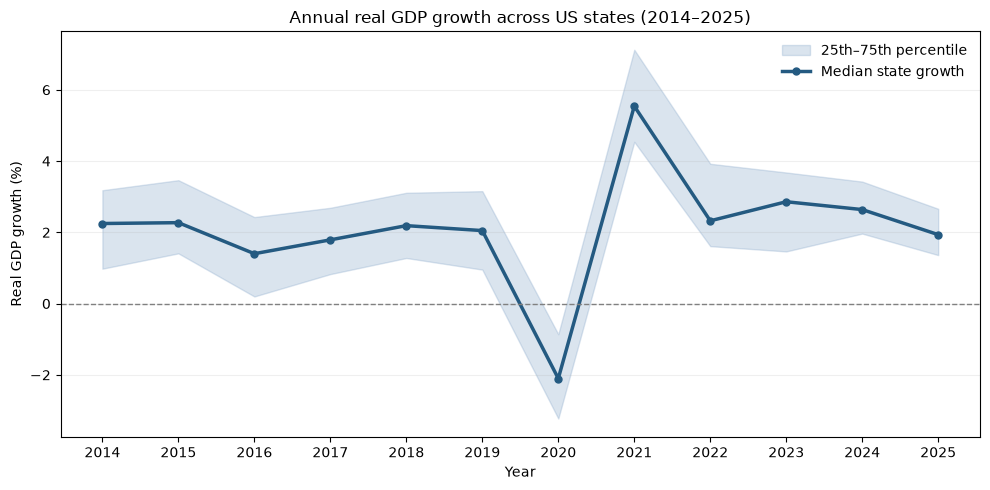

In [30]:
# Summarize annual real GDP growth across states
growth_summary = (
    economic_state.groupby("year")["real_gdp_growth_pct"]
    .agg(
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(
    growth_summary["year"],
    growth_summary["q25"],
    growth_summary["q75"],
    color="#85A6C9",
    alpha=0.3,
    label="25th–75th percentile"
)

ax.plot(
    growth_summary["year"],
    growth_summary["median"],
    color="#245A81",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Median state growth"
)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Annual real GDP growth across US states (2014–2025)",
    xlabel="Year",
    ylabel="Real GDP growth (%)"
)

ax.set_xticks(growth_summary["year"])
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "04_02_real_gdp_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### Selected industry contributions to GDP (2025)

The chart compares the economic contributions of the ten selected industries across the 50 US states.

Industry GDP shares are calculated from aggregate nominal GDP rather than averaging state percentages. The selected industries do not cover the entire economy, and their shares are therefore not expected to sum to 100%.


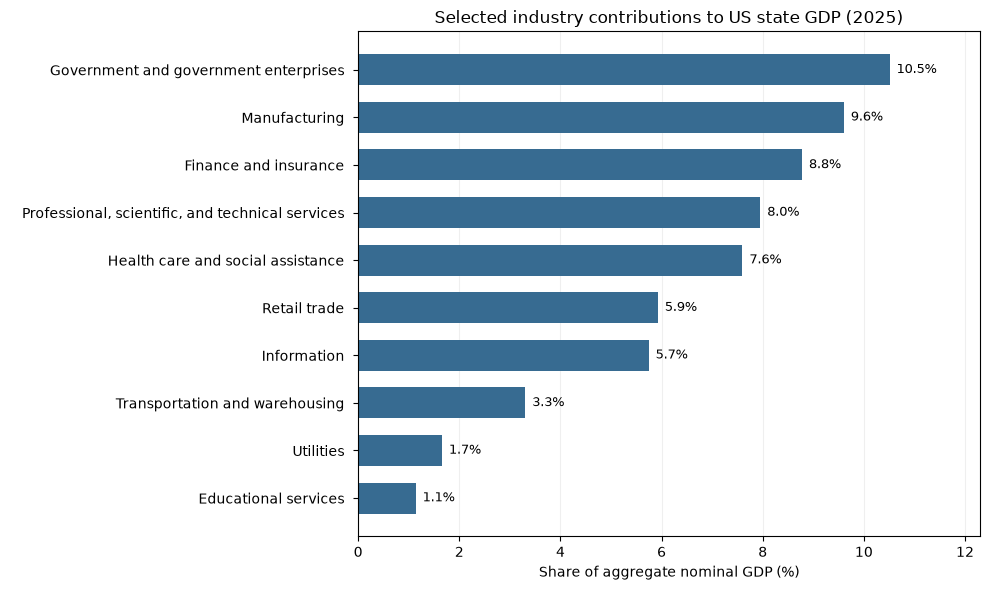

In [31]:
# Calculate aggregate GDP shares for the selected industries
sector_2025 = economic_sectors.loc[
    economic_sectors["year"] == 2025
]

total_gdp_2025 = economic_state.loc[
    economic_state["year"] == 2025, "gdp_nominal"
].sum()

sector_summary = (
    sector_2025.groupby("sector", as_index=False)["sector_gdp"]
    .sum()
)

sector_summary["share_pct"] = (
    100 * sector_summary["sector_gdp"] / total_gdp_2025
)

sector_summary = sector_summary.sort_values("share_pct")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    sector_summary["sector"],
    sector_summary["share_pct"],
    color="#376B91",
    height=0.65
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=5,
    fontsize=9
)

ax.set(
    title="Selected industry contributions to US state GDP (2025)",
    xlabel="Share of aggregate nominal GDP (%)",
    ylabel=""
)

ax.set_xlim(0, sector_summary["share_pct"].max() * 1.17)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "04_03_sector_gdp_shares.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## 5. Validation and export

The prepared datasets are validated and exported for subsequent economic analysis.

Two datasets are retained:
- **State-level economic indicators:** one observation per state and year.
- **Industry-level GDP:** one observation per state, year, and selected industry.

Both datasets cover 50 US states from 2014 to 2025. Monetary values are expressed in USD, and sector GDP shares are expressed as percentages.


In [28]:
# Validate state-level dataset
assert economic_state.shape[0] == 600
assert economic_state["state_fips"].nunique() == 50
assert economic_state["year"].nunique() == 12
assert not economic_state.duplicated(["state_fips", "year"]).any()
assert economic_state.notna().all().all()

# Validate sector-level dataset
assert economic_sectors.shape[0] == 6000
assert economic_sectors["sector"].nunique() == 10
assert not economic_sectors.duplicated(
    ["state_fips", "year", "sector"]
).any()
assert economic_sectors.notna().all().all()
assert economic_sectors["sector_gdp_share_pct"].between(0, 100).all()

validation_summary = pd.DataFrame([
    {
        "dataset": "State economic indicators",
        "rows": len(economic_state),
        "states": economic_state["state_fips"].nunique(),
        "years": economic_state["year"].nunique(),
        "missing_values": int(economic_state.isna().sum().sum()),
    },
    {
        "dataset": "Sector GDP",
        "rows": len(economic_sectors),
        "states": economic_sectors["state_fips"].nunique(),
        "years": economic_sectors["year"].nunique(),
        "missing_values": int(economic_sectors.isna().sum().sum()),
    },
])

display(validation_summary)


,dataset,rows,states,years,missing_values
0,State economic indicators,600,50,12,0
1,Sector GDP,6000,50,12,0


In [29]:
# Export validated BEA datasets
output_dir = PROJECT_ROOT / "data" / "processed" / "economic" / "bea"
output_dir.mkdir(parents=True, exist_ok=True)

state_file = output_dir / "bea_state_economic_2014_2025.csv"
sector_file = output_dir / "bea_state_sector_gdp_2014_2025.csv"

economic_state.to_csv(state_file, index=False)
economic_sectors.to_csv(sector_file, index=False)

print("Exported files:")
print(state_file)
print(sector_file)


Exported files:
C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\data\processed\economic\bea\bea_state_economic_2014_2025.csv
C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\data\processed\economic\bea\bea_state_sector_gdp_2014_2025.csv
